# Server-Side Visualization Tools in Python

**Streamlit first · Dash as optional supplemental material**

-   Goal: turn Python analyses into interactive data applications.
-   Prerequisites: basic Python, pandas, and plotting.
-   Roadmap: web visualization ecosystem → client/server → Streamlit →
    optional advanced topics.

*Lecture 1 of 2: The next packet introduces Shiny in R.*

# Introduction to Server Side Tools For visualization

## Where does a visualization run?

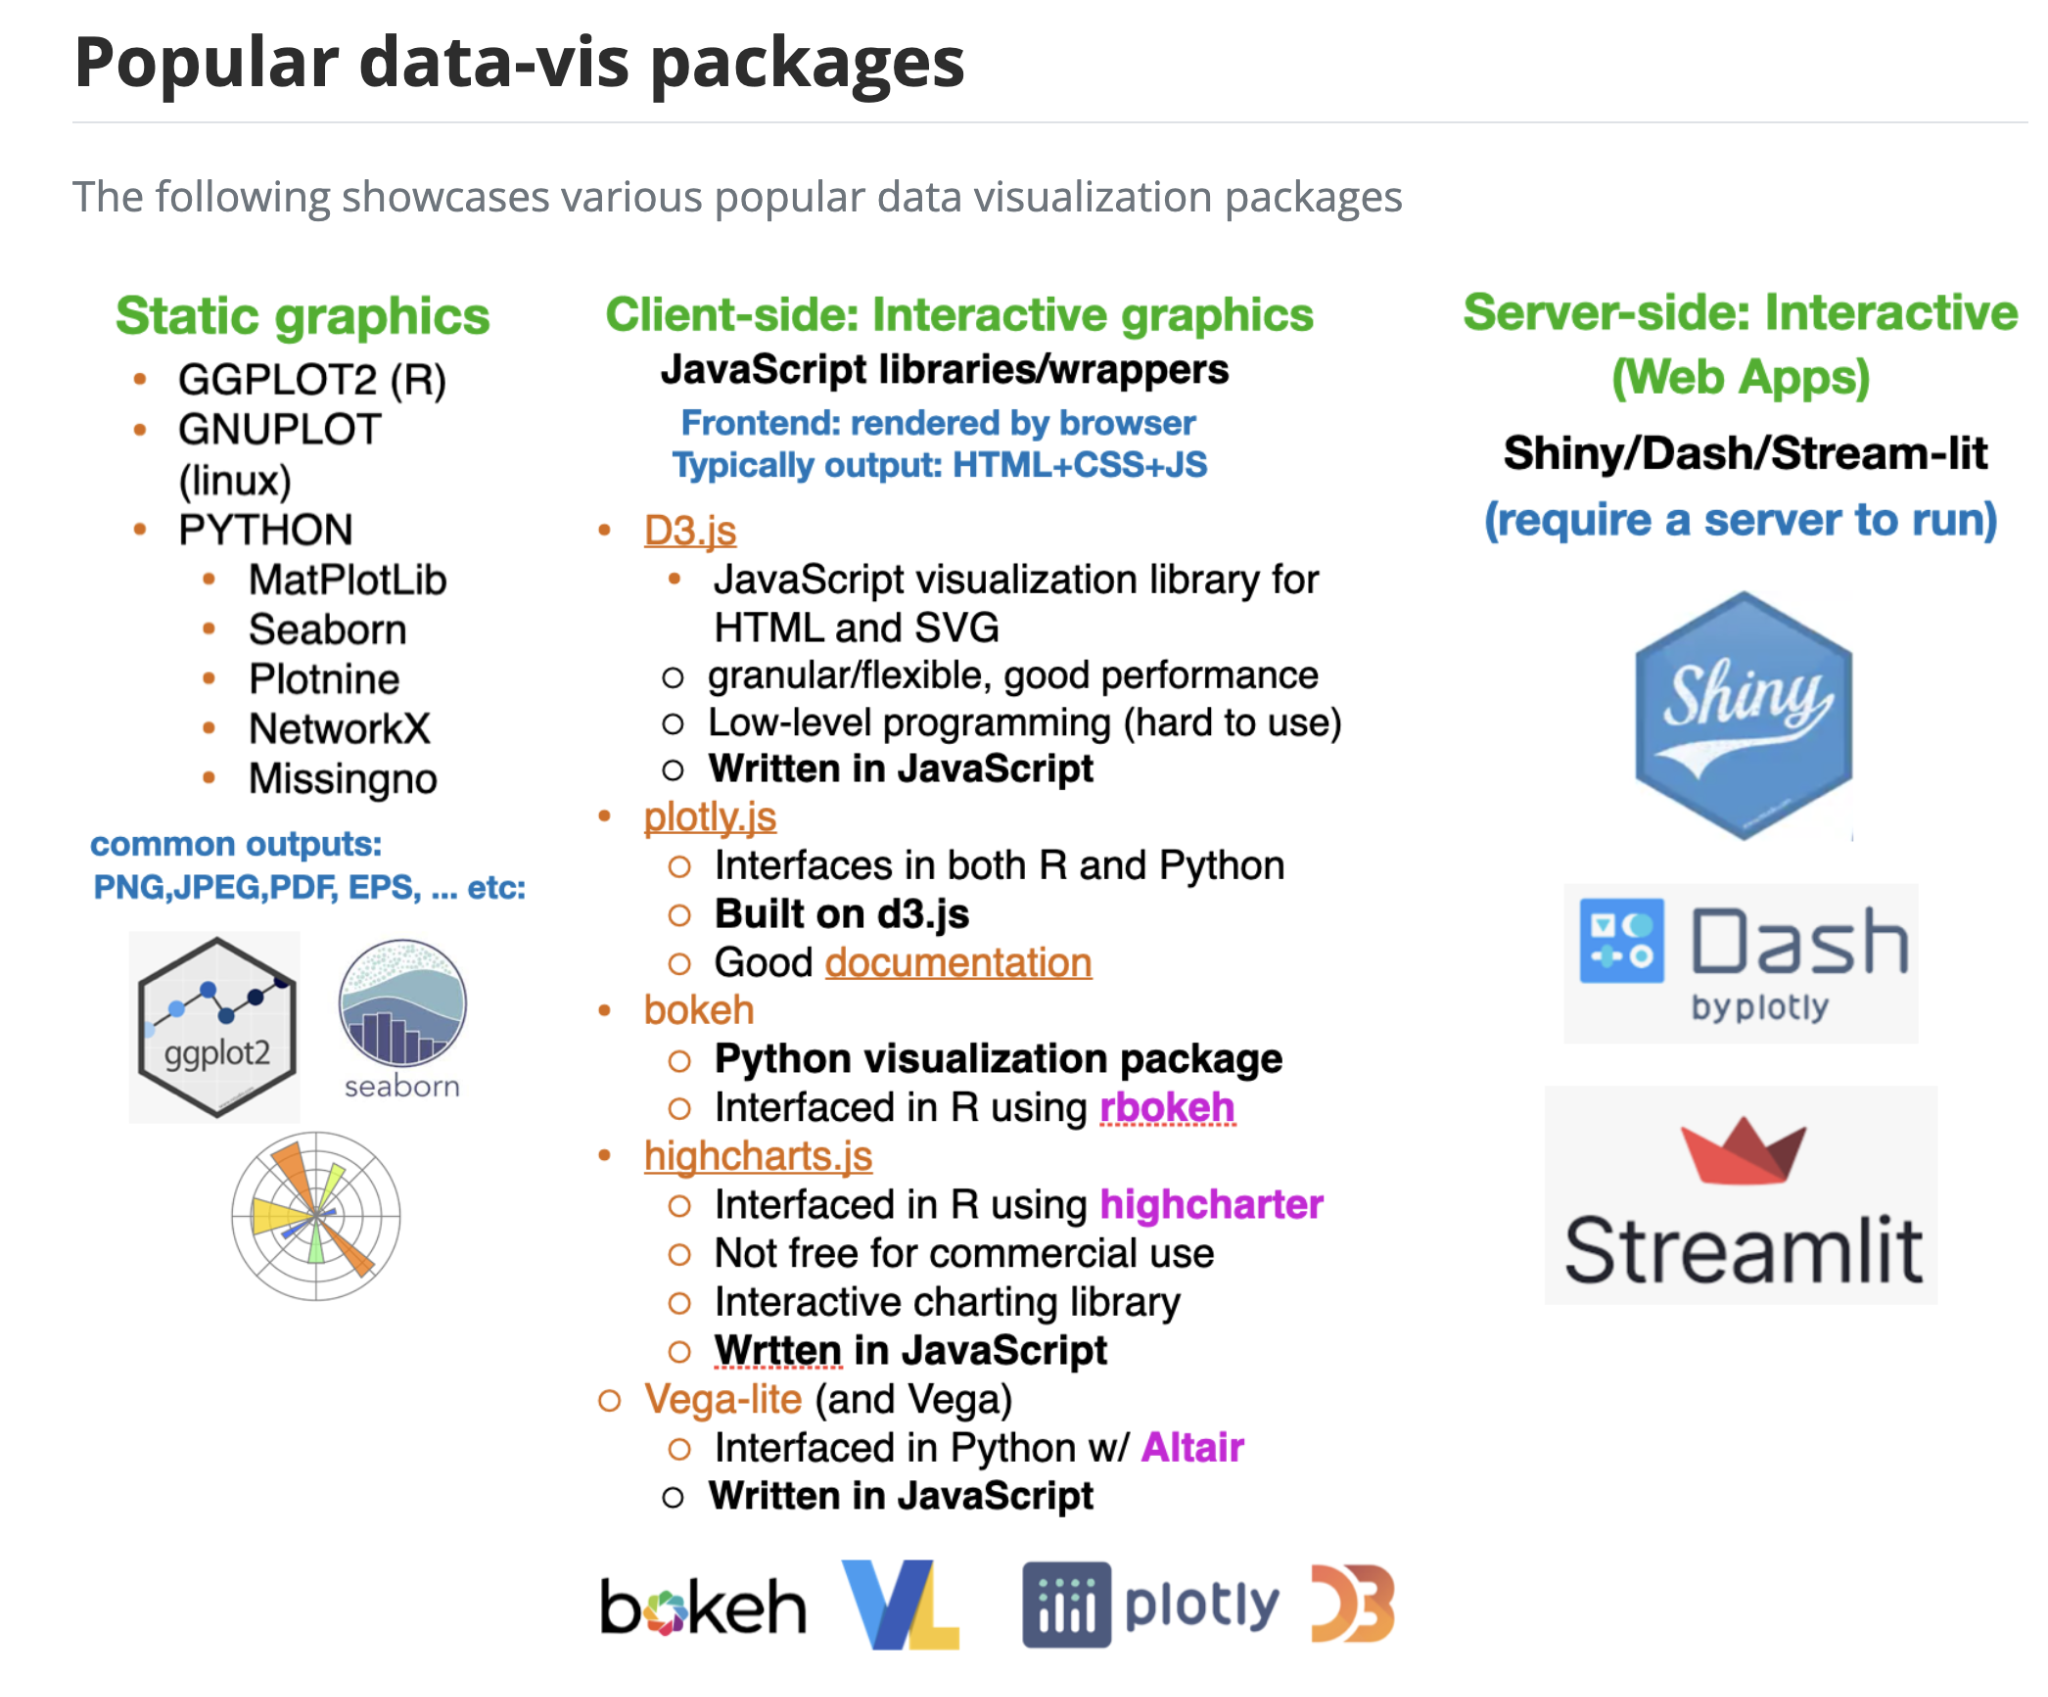

-   **Static graphic:** rendered once; export a PNG, SVG, or PDF
    (Matplotlib, Seaborn, ggplot2).
-   **Client-side interactive graphic:** browser handles zoom, hover,
    and selection (Plotly.js, Vega-Lite).
-   **Server-backed data app:** browser controls trigger Python/R
    calculations, queries, or models (Streamlit, Dash, Shiny).
-   These categories overlap: a Streamlit app can display an interactive
    Plotly chart.

## The internet in one picture

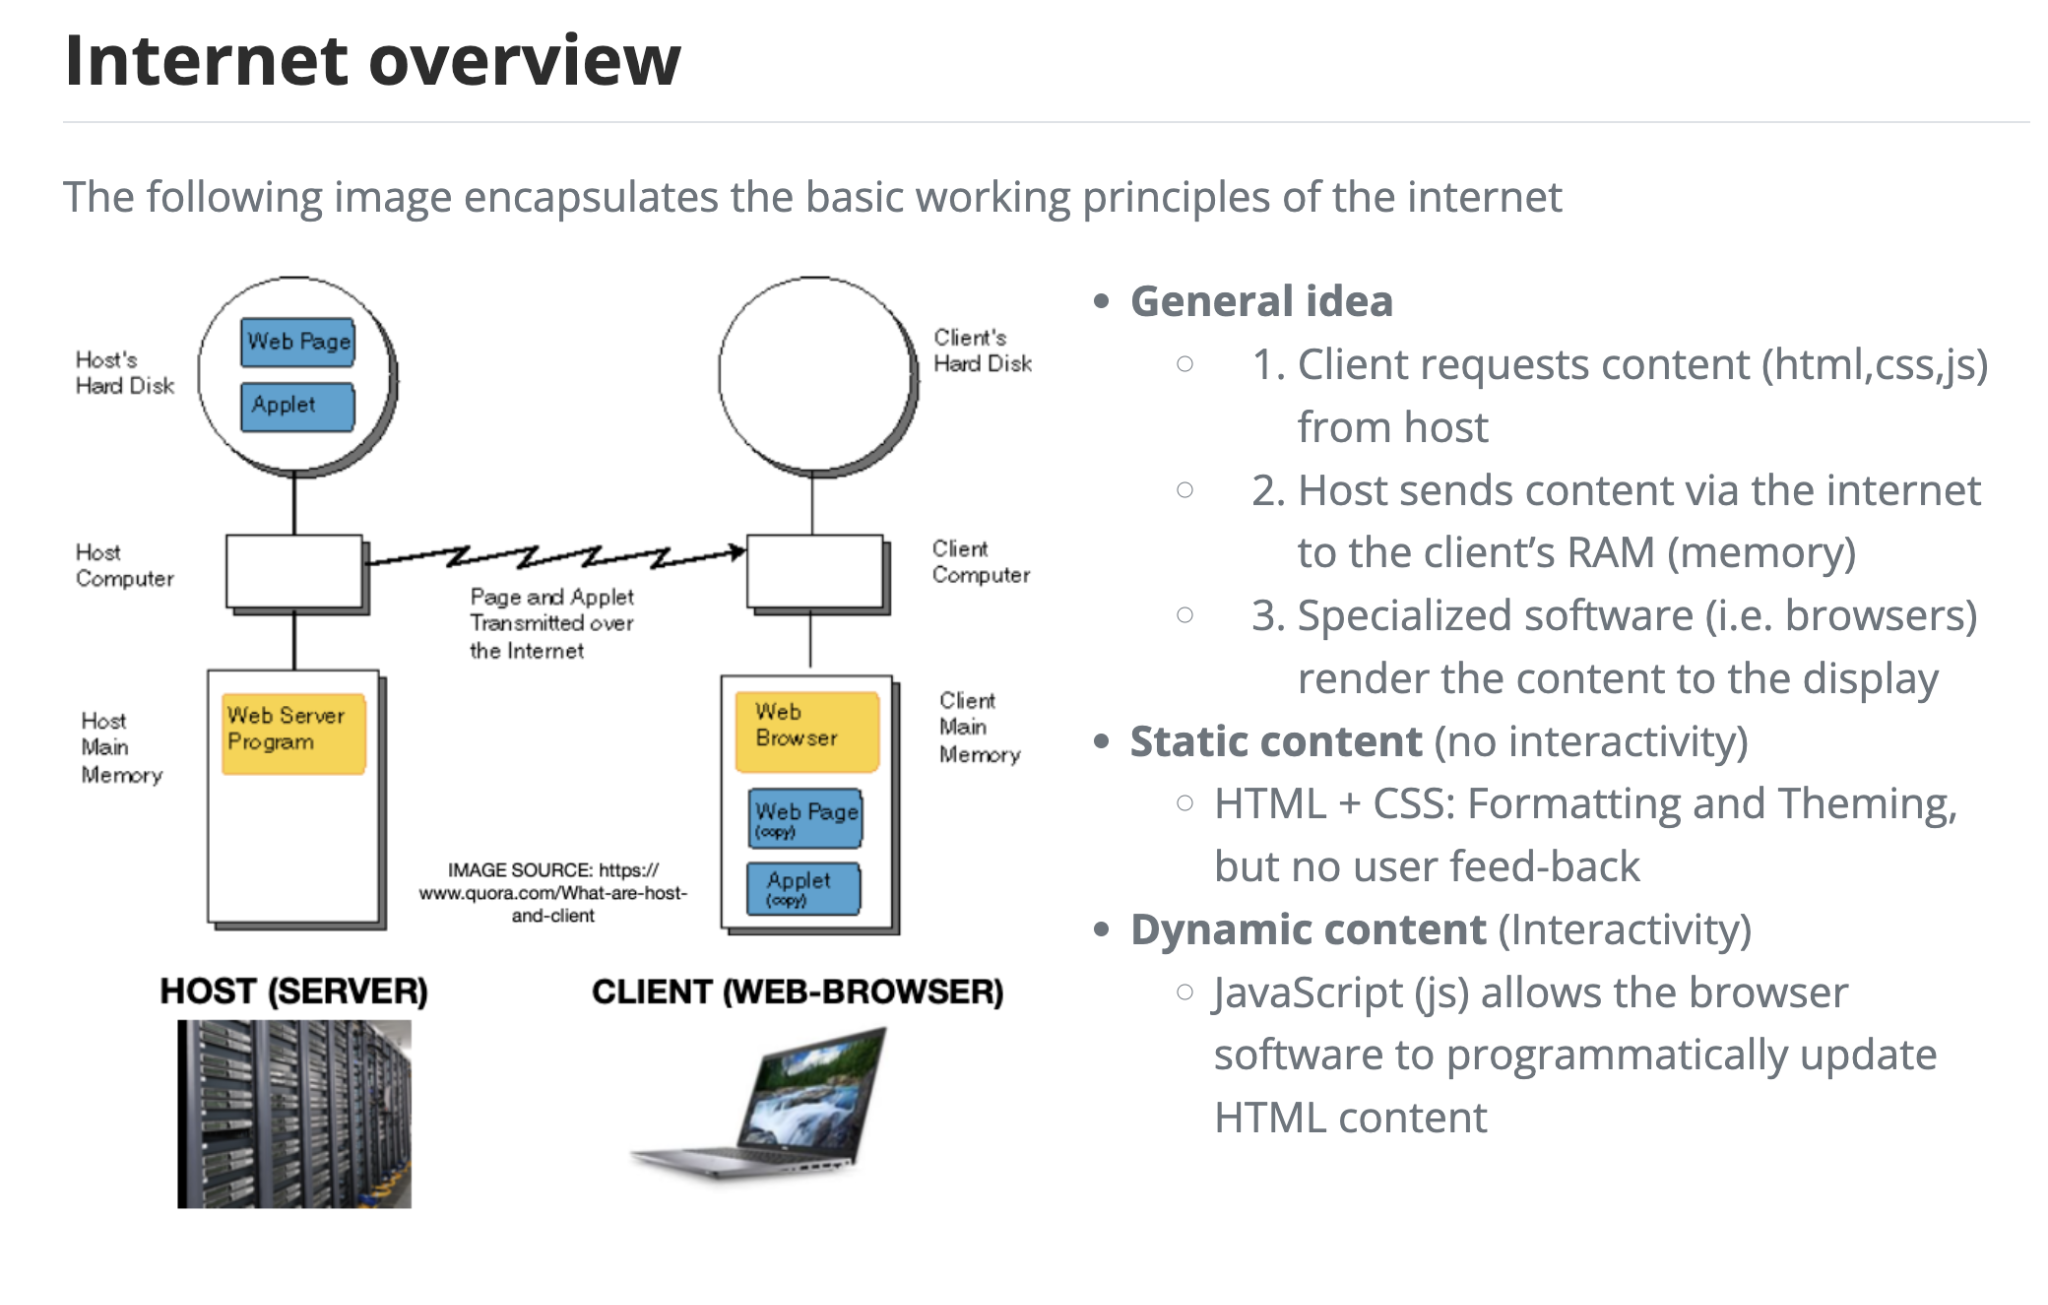

-   A **browser (client)** requests a page from a **web server**.
-   The server returns HTML, CSS, JavaScript, and possibly data.
-   The browser displays the page; later interactions may or may not
    require another server request.
-   Historical diagram note: **Java applets are obsolete**; modern web
    apps generally use JavaScript and web APIs.

## Frontend vs. backend

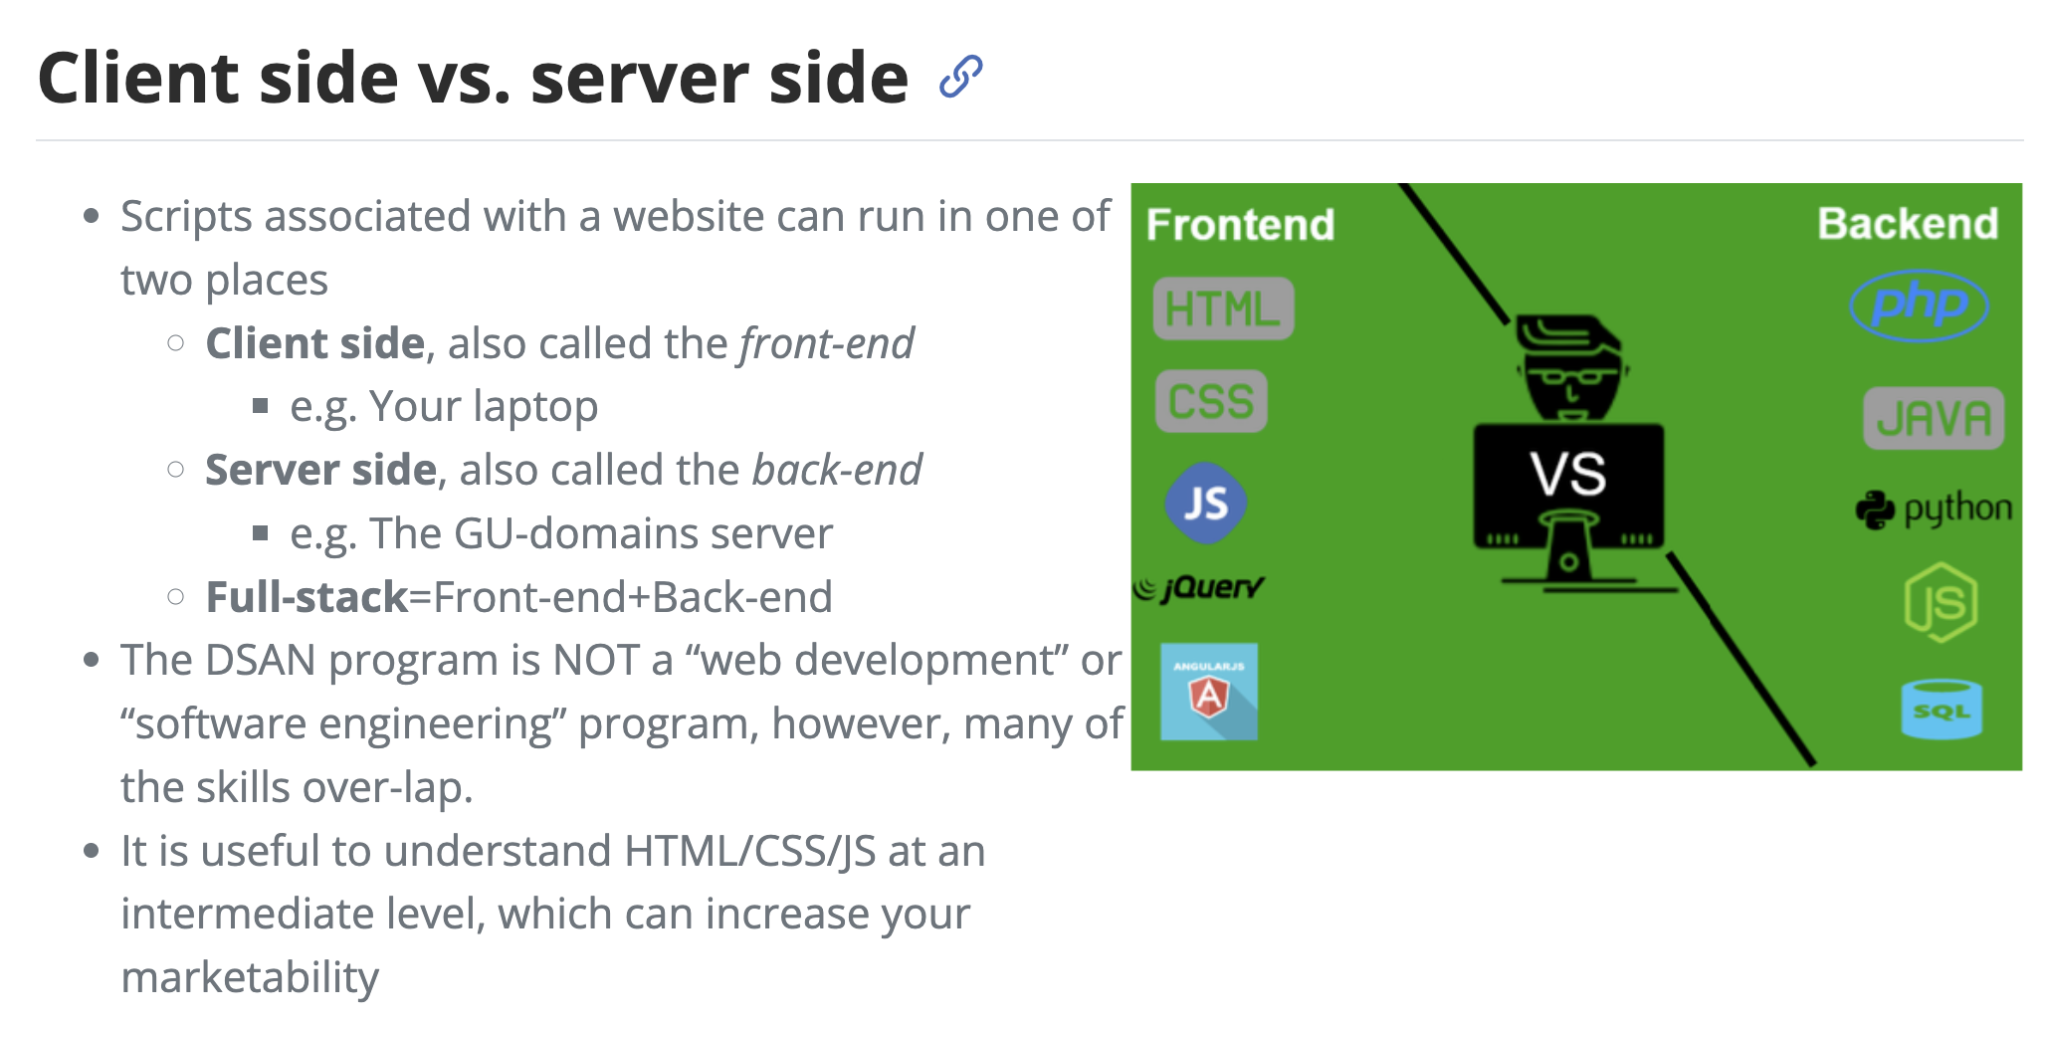

-   **Frontend (browser):** what users see and click;
    HTML/CSS/JavaScript.
-   **Backend (server):** Python/R code that loads data, runs models,
    queries databases, and returns results.
-   A *server* can be your own laptop during development—not necessarily
    a cloud machine.
-   Streamlit hides much of the web plumbing, but a server process still
    runs Python.

## Compare: Plotly HTML vs. a Streamlit app

| Question | Standalone Plotly HTML | Streamlit app |
|------------------------|------------------------|------------------------|
| Where does interaction happen? | Mostly in browser | Browser **and** Python server |
| Hover, zoom, toggle traces? | Yes | Yes (via embedded Plotly chart) |
| Re-run Python after a widget changes? | No | Yes |
| Query a database or score a model on demand? | Not without another service | Yes, from Python |
| Share as a static file? | Often yes | Requires running app server |

**Key idea:** A Plotly chart can be interactive *without* a Python
backend. A Streamlit app can recompute its data and charts when inputs
change.

## A concrete example: exploring sales

**Client-side-only:** A user hovers over a precomputed sales chart or
hides a product series.

**Server-backed:** A user chooses a region → Python filters millions of
records (or queries a database) → computes a new forecast → sends
updated results to the browser.

-   A backend unlocks fresh data, expensive computation, authentication,
    and coordinated controls.
-   Tradeoff: hosting, latency, cost, and security become important.

## How a server-backed visualization works

``` text
Browser                     Python server
[Choose a region] --------> [Read selection]
                            [Filter / query data]
                            [Compute / fit model]
[Updated chart] <---------- [Return results]
```

-   The **UI** collects inputs and presents outputs.
-   The **server** does work that cannot be packaged as a self-contained
    HTML chart.
-   A browser is still responsible for rendering the final
    visualization.

## Server-side ecosystem: Python and R

| Language | Tools | Typical strengths |
|------------------------|------------------------|------------------------|
| Python | **Streamlit** | Fast, Python-first analytical apps |
| Python | **Dash** | Explicit layouts and callback-driven apps |
| Python | Panel, Voilà, Gradio | Notebook/model interfaces and custom apps |
| R | **Shiny** | Reactive analytical apps with R |
| R | Quarto dashboards + Shiny | Reporting with optional server interactivity |

-   Both ecosystems can embed Plotly and other interactive chart
    libraries.
-   BI platforms (Power BI, Tableau) emphasize managed reporting;
    frameworks emphasize **custom behavior and computation**.

## Hosting: where does the backend live?

-   **Local:** run on your laptop for development; browser connects to
    `localhost`.
-   **Hosted:** deploy to an appropriate cloud/app platform so others
    can open a URL.
-   Hosting must keep the Python/R process running and provide required
    packages and data access.
-   Public hosting is not automatically private: avoid committing
    passwords, tokens, or sensitive datasets.
-   Containerization (e.g., Docker) can help package dependencies, but
    is **not needed for our first app**.

## Agentic coding: another way to build data apps

-   AI coding assistants can help **plan, generate, run, debug, and
    revise** application code.
-   A prompt might be: *“Build a Streamlit dashboard that filters a CSV
    and plots sales by month.”*
-   This can speed up prototyping and let analysts explore unfamiliar
    frameworks.
-   It does **not** remove the need to understand data, logic, and
    deployment.

## Working responsibly with AI-generated applications

-   Start with a clear specification: dataset, inputs, expected outputs,
    and audience.
-   Run locally; inspect the code; verify chart values against known
    examples.
-   Check dependencies, secrets, data permissions, and error handling.
-   Ask the assistant to explain each component and simplify unfamiliar
    code.
-   **Takeaway:** AI is a collaborator, not a substitute for validation.
    We may revisit full app-building workflows later in the course.

# Introduction to Streamlit

## What is Streamlit?

-   **Streamlit** is an open-source Python framework for making
    interactive data applications.
-   Write ordinary Python scripts with functions such as `st.title()`,
    `st.slider()`, and `st.plotly_chart()`.
-   Streamlit supplies the browser interface and runs your Python code
    on a server.
-   Great for prototypes, course projects, exploratory dashboards, and
    model demos.

**Mental model:** write a Python script that *describes the page*.

## Install and launch

From a terminal in your project directory:

``` bash
python -m pip install streamlit pandas plotly
```

Create a file called **`app.py`**. Run:

``` bash
streamlit run app.py
```

-   Open the local URL printed in the terminal (typically
    `http://localhost:8501`).
-   Save edits to `app.py`; Streamlit can rerun the app.
-   **Important:** Run a Streamlit app from a terminal—not as a normal
    Jupyter code cell.

## First app: text and a table

Save this as `app.py`:

``` python
import streamlit as st
import pandas as pd

st.title("My first data app")
st.write("Explore a tiny dataset with Python.")

data = pd.DataFrame({"month": ["Jan", "Feb", "Mar"],
                     "sales": [120, 150, 135]})
st.dataframe(data)
```

-   `st.title()` creates a heading.
-   `st.write()` displays text or many Python objects.
-   `st.dataframe()` provides a scrollable, interactive table.

## Add a widget: the slider

``` python
import streamlit as st

st.title("Interactive input")
minimum_sales = st.slider("Minimum sales", 0, 200, 100)
st.write("Selected threshold:", minimum_sales)
```

-   `st.slider()` returns the user’s chosen value.
-   Changing a widget typically **reruns the Python script** from top to
    bottom.
-   The widget’s current value is available on each rerun.

## Connect an input to a visualization

``` python
import pandas as pd
import plotly.express as px
import streamlit as st

sales = pd.DataFrame({
    "month": ["Jan", "Feb", "Mar", "Apr"],
    "sales": [120, 150, 135, 180],
})
threshold = st.slider("Minimum sales", 0, 200, 100)
filtered = sales[sales["sales"] >= threshold]

fig = px.bar(filtered, x="month", y="sales", title="Monthly sales")
st.plotly_chart(fig, use_container_width=True)
```

**Notice:** Python filters the data; Plotly handles chart interactions
in the browser.

## A complete small dashboard

``` python
import pandas as pd
import plotly.express as px
import streamlit as st

st.title("Sales explorer")
df = pd.DataFrame({"region": ["East", "East", "West", "West"],
                   "month": ["Jan", "Feb", "Jan", "Feb"],
                   "sales": [120, 160, 90, 140]})
region = st.selectbox("Region", sorted(df["region"].unique()))
view = df[df["region"] == region]
st.metric("Total sales", f"${view['sales'].sum():,.0f}")
st.plotly_chart(px.bar(view, x="month", y="sales"),
                use_container_width=True)
st.dataframe(view)
```

-   One selection drives a metric, chart, and table.
-   This is a *server-backed dashboard*, even though its dataset is
    small.

## Layout: organize a dashboard

``` python
import streamlit as st

st.set_page_config(page_title="Explorer", layout="wide")
st.title("Explorer")

with st.sidebar:
    year = st.selectbox("Year", [2024, 2025, 2026])

left, right = st.columns(2)
with left:
    st.metric("Selected year", year)
with right:
    st.info("Place a chart or table here.")
```

-   **Sidebar:** controls that affect the whole page.
-   **Columns:** place related outputs side by side.
-   `st.set_page_config()` belongs near the beginning of the script.

## Loading your own data

``` python
import pandas as pd
import streamlit as st

uploaded = st.file_uploader("Choose a CSV", type="csv")
if uploaded is not None:
    df = pd.read_csv(uploaded)
    st.write("Rows:", len(df))
    st.dataframe(df.head())
else:
    st.info("Upload a CSV to begin.")
```

-   Files are supplied by the user through the browser.
-   Validate file types, column names, and missing values before
    plotting.
-   Do not assume that a shared app’s uploads are appropriate for
    sensitive data.

## Streamlit’s rerun model

-   The script normally runs **top to bottom** when a user changes a
    widget.
-   Widget values are re-created from the current browser session.
-   This makes small apps simple, but repeated data loading can be slow.
-   Ask: *Which operations should happen on every interaction?*

## Build a useful app: checklist

1.  Identify the **question** the dashboard should answer.
2.  Load and validate the dataset.
3.  Add **one meaningful control** (region, year, category).
4.  Compute a filtered view in Python.
5.  Display a chart and a summary metric.
6.  Test extreme selections and empty results.
7.  Share the app only after checking its data and access permissions.

## Knowledge check

-   If you export a Plotly figure to HTML, does it require a running
    Python server to hover and zoom?
-   What changes when a Streamlit slider is moved?
-   Why might a server-backed dashboard be more powerful than a static
    HTML report?
-   What additional responsibility appears when an app is deployed
    publicly?

# Going Deeper with Streamlit (Optional)

## Cache expensive work

``` python
import pandas as pd
import streamlit as st

@st.cache_data
def load_data(path):
    return pd.read_csv(path)

df = load_data("sales.csv")
st.dataframe(df.head())
```

-   `st.cache_data` is for reusable **data results**; cache entries can
    be shared across sessions.
-   Use `st.cache_resource` for reusable resources such as model objects
    or connections.
-   Choose caching carefully when data changes or contains user-specific
    information.

## Remember values across reruns

``` python
import streamlit as st

if "clicks" not in st.session_state:
    st.session_state.clicks = 0

if st.button("Count a click"):
    st.session_state.clicks += 1

st.write("Clicks in this session:", st.session_state.clicks)
```

-   `st.session_state` retains values for a user session across reruns.
-   Forms, tabs, multipage navigation, and callbacks offer additional
    control.

## Deployment and reproducibility

-   Keep `app.py` and a dependency file (such as `requirements.txt`)
    together.
-   Test locally from a clean environment before publishing.
-   Use a Streamlit-compatible hosting service or your own
    server/container.
-   Store secrets using platform-supported secret management—not in Git.
-   Check server logs, package versions, data access, and user
    permissions.

# Optional Supplemental Material: Dash

## Where Dash fits

-   **Dash** is a Python framework from Plotly for interactive web
    applications.
-   Uses explicit **layout components** and **callbacks** to connect
    inputs to outputs.
-   Often useful when you want more precise control over how UI events
    update specific outputs.
-   Streamlit usually offers a shorter path to a first analytical
    dashboard.
-   Both require a running Python app server for server-side
    functionality.

## Minimal Dash example

Install: `python -m pip install dash plotly`

``` python
from dash import Dash, dcc, html, Input, Output
import plotly.express as px

app = Dash(__name__)
app.layout = html.Div([
    dcc.Slider(1, 5, 1, id="minimum"),
    dcc.Graph(id="chart"),
])

@app.callback(Output("chart", "figure"), Input("minimum", "value"))
def update_chart(minimum):
    df = px.data.iris()
    return px.scatter(df[df.sepal_length >= minimum],
                      x="sepal_width", y="sepal_length",
                      color="species")

if __name__ == "__main__":
    app.run(debug=True)
```

Run: `python app.py`. The callback connects slider changes to the
figure.

## Further reading

-   [Streamlit documentation](https://docs.streamlit.io/)
-   [Streamlit API
    reference](https://docs.streamlit.io/develop/api-reference)
-   [Plotly Python documentation](https://plotly.com/python/)
-   [Dash documentation](https://dash.plotly.com/)

**Next lecture:** Shiny applies the same client/server ideas using R and
a reactive programming model.